In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score



## 1. Load and Inspect the Dataset

In [7]:
# Load dataset
df = pd.read_csv("aiml_training_data.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

Dataset shape: (230, 3)

Columns:
['text', 'intent', 'confidence']

First 5 rows:


,text,intent,confidence
0,Where is my order?,order_status,0.77
1,When will my package arrive?,order_status,0.91
2,Track my order please,order_status,0.75
3,Order tracking update needed,order_status,0.83
4,Has my order shipped yet?,order_status,0.90



Data types:
text              str
intent            str
confidence    float64
dtype: object


## 2. Check Missing Values and Duplicates

In [8]:
print("Missing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:


text          0
intent        0
confidence    0
dtype: int64


Duplicate rows: 0


## 3. Feature Engineering — TF-IDF Text Features

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from scipy.sparse import hstack

# Target
y = df["confidence"]

# Convert text into numerical TF-IDF features
tfidf = TfidfVectorizer(max_features=100)
X_text = tfidf.fit_transform(df["text"])

# Encode intent
encoder = OneHotEncoder(handle_unknown="ignore")
X_intent = encoder.fit_transform(df[["intent"]])

# Combine both feature sets
X = hstack([X_text, X_intent])

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (230, 106)
Target shape: (230,)


## 4. Encode Categorical Features — Intent

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from scipy.sparse import hstack

y = df["confidence"]

tfidf = TfidfVectorizer(max_features=100)
X_text = tfidf.fit_transform(df["text"])

encoder = OneHotEncoder(handle_unknown="ignore")
X_intent = encoder.fit_transform(df[["intent"]])

print("Text features:", X_text.shape)
print("Intent features:", X_intent.shape)

Text features: (230, 100)
Intent features: (230, 6)


## 5. Combine Text and Categorical Features

In [11]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from scipy.sparse import hstack
from sklearn.model_selection import train_test_split

# Load dataset
df = pd.read_csv("aiml_training_data.csv")

# Target
y = df["confidence"]

# Convert text to numerical TF-IDF features
tfidf = TfidfVectorizer(max_features=100)
X_text = tfidf.fit_transform(df["text"])

# Encode intent
encoder = OneHotEncoder(handle_unknown="ignore")
X_intent = encoder.fit_transform(df[["intent"]])

# Combine features
X = hstack([X_text, X_intent])

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X shape:", X.shape)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X shape: (230, 106)
X_train shape: (184, 106)
X_test shape: (46, 106)
y_train shape: (184,)
y_test shape: (46,)


## 7. Train-Test Split

In [12]:
from sklearn.linear_model import LinearRegression

# Create and train the model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Make predictions
linear_predictions = linear_model.predict(X_test)

print("Linear Regression model trained successfully.")

print("\nIntercept:", linear_model.intercept_)

print("\nCoefficients:")
for i, coefficient in enumerate(linear_model.coef_):
    print(f"Feature {i}: {coefficient:.4f}")

Linear Regression model trained successfully.

Intercept: 0.8430170963702656

Coefficients:
Feature 0: -0.1116
Feature 1: 0.0000
Feature 2: -0.1433
Feature 3: 0.0000
Feature 4: 0.1479
Feature 5: -0.1196
Feature 6: 0.1069
Feature 7: -0.1350
Feature 8: -0.0363
Feature 9: -0.0251
Feature 10: 0.0874
Feature 11: 0.0080
Feature 12: 0.0000
Feature 13: 0.1585
Feature 14: -0.0487
Feature 15: 0.0000
Feature 16: 0.0289
Feature 17: 0.0674
Feature 18: -0.0014
Feature 19: -0.0498
Feature 20: 0.0000
Feature 21: -0.0261
Feature 22: 0.0312
Feature 23: 0.0000
Feature 24: 0.1576
Feature 25: 0.0104
Feature 26: -0.0960
Feature 27: 0.0000
Feature 28: -0.1077
Feature 29: 0.0289
Feature 30: -0.1196
Feature 31: 0.0000
Feature 32: 0.0000
Feature 33: 0.0196
Feature 34: -0.0244
Feature 35: 0.1810
Feature 36: 0.0196
Feature 37: 0.0000
Feature 38: 0.0000
Feature 39: 0.1188
Feature 40: -0.1782
Feature 41: 0.1050
Feature 42: 0.1595
Feature 43: 0.1362
Feature 44: 0.0000
Feature 45: 0.0000
Feature 46: 0.0000
Feature 47

## 8. Train Linear Regression Model

In [13]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Calculate evaluation metrics
mse = mean_squared_error(y_test, linear_predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, linear_predictions)
r2 = r2_score(y_test, linear_predictions)

print("Linear Regression Evaluation")
print("----------------------------")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"R²   : {r2:.4f}")

Linear Regression Evaluation
----------------------------
MSE  : 0.0076
RMSE : 0.0874
MAE  : 0.0740
R²   : -0.1768


## 9. Predicted vs Actual Values

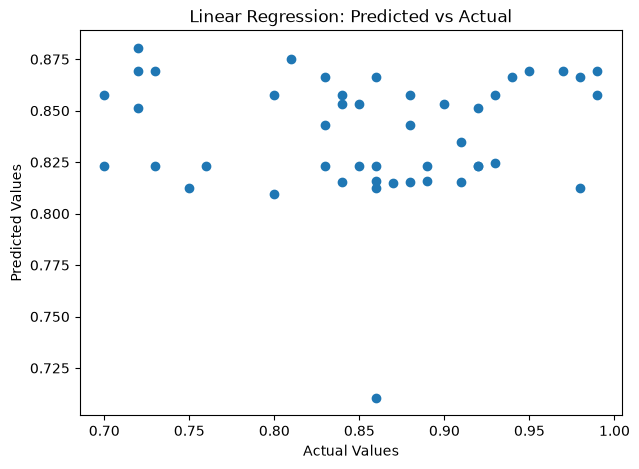

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(y_test, linear_predictions)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Linear Regression: Predicted vs Actual")

plt.show()

## 10. Residual Plot

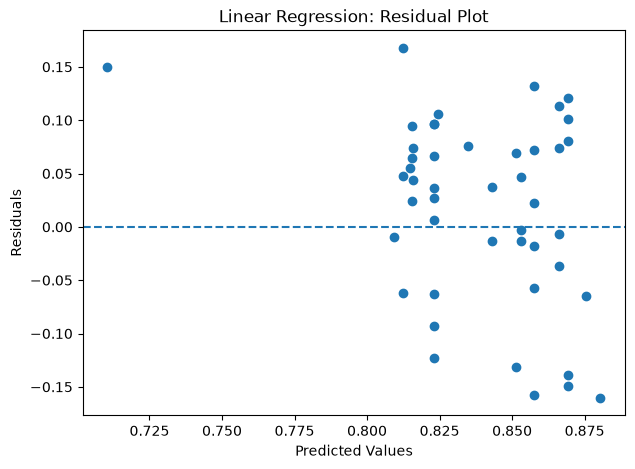

In [15]:
# Calculate residuals
residuals = y_test - linear_predictions

plt.figure(figsize=(7, 5))

plt.scatter(linear_predictions, residuals)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Linear Regression: Residual Plot")

plt.show()

## 11. Train Ridge and Lasso Regression Models

In [16]:
from sklearn.linear_model import Ridge, Lasso

# Create models
ridge_model = Ridge(alpha=1.0)
lasso_model = Lasso(alpha=0.1, max_iter=10000)

# Train models
ridge_model.fit(X_train, y_train)
lasso_model.fit(X_train, y_train)

# Make predictions
ridge_predictions = ridge_model.predict(X_test)
lasso_predictions = lasso_model.predict(X_test)

print("Ridge and Lasso models trained successfully.")

Ridge and Lasso models trained successfully.


## 12. Compare Linear, Ridge, and Lasso Models

In [17]:
# Predictions from all three models
model_predictions = {
    "Linear Regression": linear_predictions,
    "Ridge": ridge_predictions,
    "Lasso": lasso_predictions
}

# Calculate metrics for each model
results = []

for model_name, predictions in model_predictions.items():
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": model_name,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R²": r2
    })

# Create comparison table
comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))

,Model,MSE,RMSE,MAE,R²
0,Linear Regression,0.0076,0.0874,0.0740,-0.1768
1,Ridge,0.0072,0.0850,0.0723,-0.1127
2,Lasso,0.0068,0.0824,0.0674,-0.0463


## 13. Compare Model Coefficients

In [18]:
coefficient_comparison = pd.DataFrame({
    "Feature": range(X.shape[1]),
    "Linear Regression": linear_model.coef_,
    "Ridge": ridge_model.coef_,
    "Lasso": lasso_model.coef_
})

display(coefficient_comparison.round(4))

,Feature,Linear Regression,Ridge,Lasso
0,0,-0.1116,-0.0482,0.0
1,1,0.0000,0.0000,0.0
2,2,-0.1433,-0.0570,0.0
3,3,0.0000,0.0000,0.0
4,4,0.1479,0.0626,0.0
...,...,...,...,...
101,101,-0.0281,-0.0188,0.0
102,102,0.0545,0.0305,0.0
103,103,-0.0126,-0.0114,0.0
104,104,0.0053,0.0099,0.0
